# ALM delay-decision task (Dandiset 000363): exploration + Grassmannian pipeline

Part 1 keeps the exploration of [Dandiset 000363](https://dandiarchive.org/dandiset/000363)
(Chen et al. 2024): which brain regions each session records, one streamed session's units and
trial structure, and a check that spikes are confined to trials. Nothing is downloaded: files are
streamed from S3 with `remfile` byte ranges; the region survey caches to a CSV next to the notebook.

Part 2 runs the standardised Grassmannian pipeline on that session in **trials** mode (bins and
covariance windows live inside each non-photostim trial).

In [1]:
# ============ storage and run naming: inputs and outputs both live under storage/ ============
from pathlib import Path

STORAGE_DIR   = Path("../../storage").resolve()                 # same storage root the downloads always used
DOWNLOAD_DIR  = STORAGE_DIR / "dandi_downloads"                  # INPUTS only (NWB files)
DATASET_LABEL = "ALM_000363"
RUN_NAME      = "basic_grassmanian"                              # name of this run; change it to keep runs apart
DATASET_DIR   = STORAGE_DIR / "grassmanian_test" / DATASET_LABEL     # dataset-level caches: region survey, loaded sessions
OUTPUT_DIR    = DATASET_DIR / RUN_NAME                               # this run's caches (window spectra, Gr mean), per session
DATASET_DIR.mkdir(parents=True, exist_ok=True)
DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)
# Only data that saves recomputation is written; figures are displayed, not saved.
print("inputs :", DOWNLOAD_DIR)
print("caches :", OUTPUT_DIR)

inputs : /notebooks/CumulantDynamicsGuiltByAssociation/Hydrangea_demo/Validating_Hybrid_Dynamics/storage/dandi_downloads
caches : /notebooks/CumulantDynamicsGuiltByAssociation/Hydrangea_demo/Validating_Hybrid_Dynamics/storage/grassmanian_test/ALM_000363/basic_grassmanian


In [2]:
# ----------------------------- config ---------------------------------
import time
import itertools
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import h5py
import remfile
import pynwb
from dandi.dandiapi import DandiAPIClient

DANDISET_ID = "000363"
SURVEY_CACHE = DATASET_DIR / "region_survey_000363.csv"   # storage/grassmanian_test/ALM_000363/
if not SURVEY_CACHE.exists() and Path("region_survey_000363.csv").exists():   # reuse an old cache
    import shutil; shutil.copy("region_survey_000363.csv", SURVEY_CACHE)
SURVEY_LIMIT = None      # int for a quick pass (e.g. 25); None = all 174 sessions

CHOSEN_PATH = None       # None = auto-pick the surveyed session with most regions

# binning / embedding
BIN_MS = 10.0            # spike-count bin width for the covariance/correlation
K_MAX = 10               # keep top-K PCs: the spectrum's elbow, capped at this
PAD_S = 5.0              # seconds kept before the first / after the last trial
MIN_RATE_HZ = 0.1        # drop near-silent units
MIN_UNITS_REGION = 15    # regions with fewer good units skip the per-region trace

# detection, same spirit as the bouncing-ball demo: free flight has a steady
# quotient, a reset is a huge isolated spike above a robust baseline
THRESH_MULT = 5.0        # threshold = THRESH_MULT * median(||dv||/dt)

ZOOM_START = None        # seconds; None = auto (a little before the 10th go cue)
ZOOM_DUR = 30.0          # seconds shown in the zoomed trace figure

## 1. Region survey across all sessions

The DANDI asset metadata does not carry region labels, so for each NWB file we
stream only what we need: `electrodes/location`, the unit count, and the
unit → electrode mapping (so regions are counted by *units actually recorded
there*, not just by electrode placement). A couple of small int/str arrays per
file — a few seconds each, not 300 GB.

In [3]:
import json


def _decode(arr):
    """HDF5 string data to a plain numpy array of str."""
    return np.array([x.decode() if isinstance(x, (bytes, bytearray)) else str(x)
                     for x in np.asarray(arr)])


def region_name(loc):
    """Brain region from an electrode `location` string.

    000363 stores a JSON blob per electrode, e.g.
    {"brain_regions": "left ALM", "ap_location": ..., ...}; other datasets
    store the plain name. Either way, return just the region."""
    s = str(loc).strip()
    if s.startswith("{"):
        try:
            return str(json.loads(s).get("brain_regions", "")).strip()
        except ValueError:
            pass
    return s


def _ragged(group, col):
    """A DynamicTable ragged column as a list of per-row arrays."""
    data = group[col][:]
    if col + "_index" in group:
        return np.split(data, group[col + "_index"][:-1])
    return [np.atleast_1d(v) for v in data]


def open_stream(asset):
    url = asset.get_content_url(follow_redirects=1, strip_query=True)
    return h5py.File(remfile.File(url), "r")


def survey_session(asset):
    """One row of the survey: regions present and units per region."""
    sub, fname = asset.path.split("/", 1)
    row = {"path": asset.path, "subject": sub.replace("sub-", ""),
           "size_gb": round(asset.size / 1e9, 1),
           "n_electrodes": 0, "n_units": 0, "regions": "", "units_per_region": "",
           "error": ""}
    with open_stream(asset) as f:
        elec = f.get("general/extracellular_ephys/electrodes")
        if elec is None or "location" not in elec:
            row["error"] = "no electrodes table"
            return row
        loc = np.array([region_name(s) for s in _decode(elec["location"][:])])
        row["n_electrodes"] = len(loc)

        units = f.get("units")
        per_region = Counter()
        if units is not None and "id" in units:
            row["n_units"] = len(units["id"])
            if "electrodes" in units:
                # region of a unit = location of its first electrode
                first_elec = [int(e[0]) for e in _ragged(units, "electrodes") if len(e)]
                per_region = Counter(loc[first_elec])
        if not per_region:               # fall back to electrode placement
            per_region = Counter(loc)
        per_region = Counter({k: v for k, v in per_region.items()
                              if k and k.lower() not in ("none", "n/a", "unknown")})
        row["regions"] = ";".join(sorted(per_region))
        row["units_per_region"] = ";".join(
            "%s=%d" % kv for kv in sorted(per_region.items()))
    return row


In [4]:
def _clean_row(row):
    """Region labels via region_name -- also fixes rows cached before it existed."""
    row = dict(row)
    per_region = Counter()
    for item in str(row.get("units_per_region", "") or "").split(";"):
        if "=" in item:
            name, n = item.rsplit("=", 1)
            name = region_name(name)
            if name:
                per_region[name] += int(float(n))
    row["regions"] = ";".join(sorted(per_region))
    row["units_per_region"] = ";".join("%s=%d" % kv for kv in sorted(per_region.items()))
    return row


cache = {}
if SURVEY_CACHE.exists():
    cache = {r["path"]: dict(r) for _, r in pd.read_csv(
        SURVEY_CACHE, keep_default_na=False).iterrows()}

with DandiAPIClient() as client:
    dandiset = client.get_dandiset(DANDISET_ID, "draft")
    assets = sorted((a for a in dandiset.get_assets() if a.path.endswith(".nwb")),
                    key=lambda a: a.path)
    if SURVEY_LIMIT is not None:
        assets = assets[:SURVEY_LIMIT]
    todo = [a for a in assets
            if not (a.path in cache and not cache[a.path].get("error"))]
    print("%d sessions: %d cached, %d to stream" % (
        len(assets), len(assets) - len(todo), len(todo)))

    t_start = time.time()
    for i, asset in enumerate(todo):
        try:
            row = survey_session(asset)
        except Exception as exc:                       # keep going, log the file
            row = {"path": asset.path, "error": "%s: %s" % (type(exc).__name__, exc)}
        cache[asset.path] = row
        pd.DataFrame(cache.values()).to_csv(SURVEY_CACHE, index=False)
        print("\r  streamed %3d/%3d  (%4.0fs)  %-70s" % (
            i + 1, len(todo), time.time() - t_start, asset.path), end="", flush=True)
    print()

# ---------------------------- summary ------------------------------------
survey = pd.DataFrame([_clean_row(r) for r in cache.values()])
survey["error"] = survey["error"].fillna("").astype(str)
failed = survey[survey["error"] != ""]
survey = survey[survey["error"] == ""].reset_index(drop=True)
survey["session"] = survey["path"].str.extract(r"ses-([^_]+)")[0]
survey["n_units"] = pd.to_numeric(survey["n_units"], errors="coerce").fillna(0).astype(int)
survey["n_regions"] = survey["regions"].map(lambda r: len([x for x in r.split(";") if x]))

print("surveyed OK: %d sessions, %d subjects, %d failed" % (
    len(survey), survey["subject"].nunique(), len(failed)))

# long form: one row per (session, region)
long = pd.DataFrame([
    {"path": r.path, "subject": r.subject, "region": name, "units": int(n)}
    for r in survey.itertuples()
    for name, n in (x.rsplit("=", 1) for x in r.units_per_region.split(";") if "=" in x)
])

# 1) how many regions do sessions record at once?
by_count = (survey.groupby("n_regions")
            .agg(sessions=("path", "size"), subjects=("subject", "nunique"),
                 median_units=("n_units", "median"))
            .sort_index(ascending=False))
print("\nsessions by number of simultaneously recorded regions:")
display(by_count)

# 2) per region: how many sessions / subjects / units
region_table = (long.groupby("region")
                .agg(sessions=("path", "nunique"), subjects=("subject", "nunique"),
                     total_units=("units", "sum"), median_units=("units", "median"))
                .sort_values("sessions", ascending=False))
print("\nper region:")
display(region_table)

# 3) the sessions with the most regions
top_sessions = (survey.sort_values(["n_regions", "n_units"], ascending=False)
                [["subject", "session", "n_regions", "n_units", "regions"]]
                .assign(regions=lambda d: d["regions"].str.replace(";", ", "))
                .head(15).reset_index(drop=True))
print("\ntop 15 sessions by number of regions:")
display(top_sessions)

if len(failed):
    print("\nfailed sessions:")
    display(failed[["path", "error"]].reset_index(drop=True))


A newer version (0.81.0) of dandi/dandi-cli is available. You are using 0.80.0


174 sessions: 0 cached, 174 to stream
  streamed 174/174  ( 272s)  sub-484677/sub-484677_ses-20210420T170516_behavior+ecephys+ogen.nwb   nwb
surveyed OK: 174 sessions, 28 subjects, 0 failed

sessions by number of simultaneously recorded regions:


,sessions,subjects,median_units
n_regions,,,
5,1,1,2367.0
4,114,24,1783.0
3,56,17,1013.5
2,3,3,892.0



per region:


,sessions,subjects,total_units,median_units
region,,,,
left ALM,108,28,44515,403.0
right ALM,103,28,41839,397.0
right Midbrain,68,22,25968,375.5
left Midbrain,68,20,24645,374.5
right Striatum,57,19,23795,394.0
left Striatum,54,19,20844,379.0
left Thalamus,45,15,23981,489.0
right Thalamus,36,13,18406,468.5
right Medulla,24,8,11913,360.5



top 15 sessions by number of regions:


,subject,session,n_regions,n_units,regions
0,480133,20201230T112558,5,2367,"left ALM, left Midbrain, left Thalamus, right ..."
1,480928,20210128T133949,4,3191,"left ALM, left Thalamus, right ALM, right Thal..."
2,479121,20200924T134307,4,2778,"left ALM, left Medulla, right ALM, right Medulla"
3,480928,20210130T135022,4,2699,"left ALM, left BLA, right ALM, right BLA"
4,479121,20200923T151145,4,2685,"left ALM, left Medulla, right ALM, right Medulla"
5,480134,20210108T135220,4,2648,"left ECT, left Striatum, right Midbrain, right..."
6,480928,20210129T132207,4,2632,"left ALM, left Thalamus, right ALM, right Thal..."
7,480134,20210113T125455,4,2619,"left ALM, left Thalamus, right ALM, right Thal..."
8,480928,20210127T140737,4,2596,"left ALM, left Thalamus, right ALM, right Thal..."
9,484677,20210418T132006,4,2506,"left Medulla, right ALM, right Midbrain, right..."


14 distinct region labels: left ALM, left BLA, left ECT, left Medulla, left Midbrain, left Striatum, left Thalamus, right ALM, right BLA, right ECT, right Medulla, right Midbrain, right Striatum, right Thalamus

sessions with the most regions at once:
                                                               path subject  n_regions  n_units                                                       regions
sub-480133/sub-480133_ses-20201230T112558_behavior+ecephys+ogen.nwb  480133          5     2367 left ALM;left Midbrain;left Thalamus;right ALM;right Thalamus
sub-480928/sub-480928_ses-20210128T133949_behavior+ecephys+ogen.nwb  480928          4     3191               left ALM;left Thalamus;right ALM;right Thalamus
sub-479121/sub-479121_ses-20200924T134307_behavior+ecephys+ogen.nwb  479121          4     2778                 left ALM;left Medulla;right ALM;right Medulla
sub-480928/sub-480928_ses-20210130T135022_behavior+ecephys+ogen.nwb  480928          4     2699                     

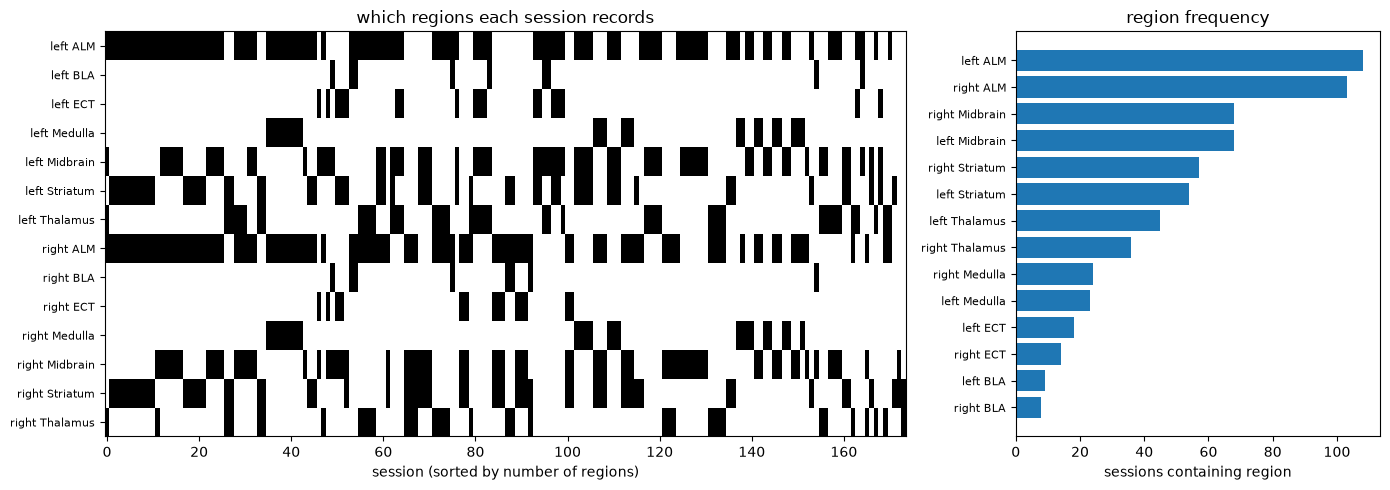

In [5]:
# ---------------- sessions x regions presence matrix -------------------
region_sets = [set(r.split(";")) - {""} for r in survey["regions"]]
all_regions = sorted(set().union(*region_sets))
presence = np.array([[reg in s for reg in all_regions] for s in region_sets])
print("%d distinct region labels: %s" % (len(all_regions), ", ".join(all_regions)))

ranked = survey.sort_values(["n_regions", "n_units"], ascending=False)
print("\nsessions with the most regions at once:")
print(ranked[["path", "subject", "n_regions", "n_units", "regions"]]
      .head(12).to_string(index=False))

order = np.argsort(-survey["n_regions"].values, kind="stable")
fig, axes = plt.subplots(1, 2, figsize=(14, 5),
                         gridspec_kw={"width_ratios": [2.2, 1]})
ax = axes[0]
ax.imshow(presence[order].T, aspect="auto", cmap="Greys", interpolation="nearest")
ax.set_yticks(range(len(all_regions)))
ax.set_yticklabels(all_regions, fontsize=8)
ax.set_xlabel("session (sorted by number of regions)")
ax.set_title("which regions each session records")

ax = axes[1]
freq = presence.sum(0)
fo = np.argsort(freq)
ax.barh(range(len(all_regions)), freq[fo], color="tab:blue")
ax.set_yticks(range(len(all_regions)))
ax.set_yticklabels(np.array(all_regions)[fo], fontsize=8)
ax.set_xlabel("sessions containing region")
ax.set_title("region frequency")
plt.tight_layout()
plt.show()

In [6]:
# -------- region combinations: what do many sessions share? ------------
# exact recorded sets
set_counts = Counter(frozenset(s) for s in region_sets)
print("most common exact region sets:")
for s, n in set_counts.most_common(10):
    print("  %3d sessions  (%d regions)  %s" % (n, len(s), ", ".join(sorted(s))))

# best k-region combination shared by the most sessions: for each k, the combo
# of regions that the largest number of sessions ALL contain
print("\nbest shared combination per combination size k:")
rows = []
for k in range(2, min(len(all_regions), 8) + 1):
    best = []
    for combo in itertools.combinations(range(len(all_regions)), k):
        n = int(presence[:, combo].all(axis=1).sum())
        if n:
            best.append((n, combo))
    if not best:
        break
    best.sort(reverse=True)
    for n, combo in best[:3]:
        rows.append({"k": k, "sessions": n,
                     "regions": ", ".join(all_regions[i] for i in combo)})
        print("  k=%d  %3d sessions  %s" % (k, n, rows[-1]["regions"]))
combo_table = pd.DataFrame(rows)

most common exact region sets:
   17 sessions  (4 regions)  left ALM, left Striatum, right ALM, right Striatum
   12 sessions  (4 regions)  left ALM, left Midbrain, right ALM, right Midbrain
   10 sessions  (4 regions)  right ALM, right ECT, right Midbrain, right Striatum
    8 sessions  (4 regions)  left ALM, left Medulla, right ALM, right Medulla
    8 sessions  (4 regions)  left ALM, left Thalamus, right ALM, right Thalamus
    7 sessions  (4 regions)  left ALM, left Midbrain, left Striatum, right Medulla
    6 sessions  (3 regions)  left ALM, left Midbrain, right Midbrain
    6 sessions  (3 regions)  left Thalamus, right ALM, right Thalamus
    6 sessions  (3 regions)  left ALM, left Midbrain, right Medulla
    6 sessions  (3 regions)  left Medulla, right ALM, right Midbrain

best shared combination per combination size k:
  k=2   60 sessions  left ALM, right ALM
  k=2   55 sessions  left ALM, left Midbrain
  k=2   48 sessions  right ALM, right Midbrain
  k=3   20 sessions  right A

## 2. One session: units, trials, continuity

Pick the session with bilateral ALM + bilateral thalamus (override with `CHOSEN_PATH`), stream it,
and build a light units table — spike times, region, quality — without pulling waveforms or raw ephys.
The `h5f` / `nwb` / `asset` objects created here are handed to the pipeline below.

In [7]:
# ------------------- choose the session --------------------------------
CHOSEN_SUBJECT = "480928"            # bilateral ALM + bilateral thalamus
CHOSEN_SESSION = "20210128T133949"   # most units of the 4-region sessions

match = survey[(survey["subject"].astype(str) == CHOSEN_SUBJECT)
               & (survey["session"] == CHOSEN_SESSION)]
if len(match):
    CHOSEN_PATH = match["path"].iloc[0]
elif CHOSEN_PATH is None:
    print("session %s / %s not in survey, falling back to most-region session"
          % (CHOSEN_SUBJECT, CHOSEN_SESSION))
    CHOSEN_PATH = ranked.iloc[0]["path"]
print("loading:", CHOSEN_PATH)

with DandiAPIClient() as client:
    asset = client.get_dandiset(DANDISET_ID, "draft").get_asset_by_path(CHOSEN_PATH)
    s3_url = asset.get_content_url(follow_redirects=1, strip_query=True)

h5f = h5py.File(remfile.File(s3_url), "r")
io = pynwb.NWBHDF5IO(file=h5f, load_namespaces=True)
nwb = io.read()
print(nwb.session_description)

# --- light units table straight from the HDF5 group (skips waveforms) ---
ug = h5f["units"]
print("units table columns:", [k for k in ug.keys() if not k.endswith("_index")])

spike_trains = _ragged(ug, "spike_times")
elec_loc = np.array([region_name(s) for s in
                     _decode(h5f["general/extracellular_ephys/electrodes/location"][:])])
unit_region = np.array([elec_loc[int(e[0])] if len(e) else ""
                        for e in _ragged(ug, "electrodes")])

quality = None
for cand in ("classification", "unit_quality", "quality", "label"):
    if cand in ug:
        quality = np.array([s.strip() for s in _decode(ug[cand][:])])
        print("quality column: %r, values: %s" % (cand, dict(Counter(quality))))
        break

units = pd.DataFrame({"region": unit_region,
                      "n_spikes": [len(s) for s in spike_trains]})
units["spike_times"] = spike_trains
if quality is not None:
    units["quality"] = quality
    units = units[units["quality"].str.lower().str.contains("good")]

# ------------------- trials, photostim trials removed --------------------
trials_all = nwb.trials.to_dataframe()
# session window comes from ALL trials, so binning covers the whole session
t0 = float(trials_all["start_time"].min()) - PAD_S
t1 = float(trials_all["stop_time"].max()) + PAD_S

trials_df = trials_all
if "photostim_onset" in trials_all:
    print("photostim_onset values (first 10 distinct):",
          trials_all["photostim_onset"].astype(str).unique()[:10])
    no_stim = trials_all["photostim_onset"].astype(str).str.strip().isin(
        ["N/A", "nan", "NaN", "None", ""])
    print("photostim trials: %d of %d removed" % ((~no_stim).sum(), len(trials_all)))
    trials_df = trials_all[no_stim].reset_index(drop=True)
else:
    print("no photostim_onset column; keeping all %d trials" % len(trials_all))
    
units["rate_hz"] = units["n_spikes"] / (t1 - t0)
n_before = units["region"].value_counts()
units = units[units["rate_hz"] >= MIN_RATE_HZ].reset_index(drop=True)

unit_table = (units.groupby("region")
              .agg(units=("rate_hz", "size"),
                   median_rate_hz=("rate_hz", "median"),
                   mean_rate_hz=("rate_hz", "mean"),
                   total_spikes=("n_spikes", "sum"))
              .assign(dropped_low_rate=lambda d: n_before.reindex(d.index).fillna(0).astype(int) - d["units"])
              .sort_values("units", ascending=False))
unit_table.loc["total"] = [unit_table["units"].sum(), units["rate_hz"].median(),
                           units["rate_hz"].mean(), unit_table["total_spikes"].sum(),
                           unit_table["dropped_low_rate"].sum()]
unit_table = unit_table.astype({"units": int, "total_spikes": int, "dropped_low_rate": int})
display(unit_table.style.format({"median_rate_hz": "{:.2f}", "mean_rate_hz": "{:.2f}",
                                 "total_spikes": "{:,}"})
        .set_caption("Good units kept per region (rate ≥ %.2f Hz)" % MIN_RATE_HZ))


loading: sub-480928/sub-480928_ses-20210128T133949_behavior+ecephys+ogen.nwb

units table columns: ['amplitude_cutoff', 'anno_name', 'avg_firing_rate', 'classification', 'cumulative_drift', 'd_prime', 'drift_metric', 'duration', 'electrode_group', 'electrodes', 'halfwidth', 'id', 'is_good_trials', 'isi_violation', 'isolation_distance', 'l_ratio', 'left_trials_drift_metric', 'max_drift', 'nn_hit_rate', 'nn_miss_rate', 'obs_intervals', 'presence_ratio', 'pt_ratio', 'recovery_slope', 'repolarization_slope', 'right_trials_drift_metric', 'sampling_rate', 'silhouette_score', 'spike_times', 'spread', 'unit', 'unit_amp', 'unit_posx', 'unit_posy', 'unit_quality', 'unit_snr', 'velocity_above', 'velocity_below', 'waveform_mean', 'waveform_sd']
quality column: 'classification', values: {np.str_('unlabelled'): 2268, np.str_('good'): 923}
photostim_onset values (first 10 distinct): <StringArray>
[  'N/A', '2.640', '2.686', '2.586', '2.579', '2.724', '3.610', '3.486',
 '2.706', '2.750']
Length: 10, d

,units,median_rate_hz,mean_rate_hz,total_spikes,dropped_low_rate
region,,,,,
right Thalamus,357,4.57,5.76,"9,227,884",0
right ALM,208,1.32,2.46,"2,292,744",4
left Thalamus,185,6.87,8.24,"6,834,326",0
left ALM,166,2.18,3.25,"2,422,047",3
total,916,3.75,5.06,"20,777,001",7


In [8]:
# ------------------------- trial structure -----------------------------
print("%d trials, columns:" % len(trials_df), list(trials_df.columns))
display(trials_df.head())

# task epoch events (sample / delay / go cues) live in BehavioralEvents
events = {}
beh = nwb.acquisition.get("BehavioralEvents")
if beh is not None:
    for name, ts in beh.time_series.items():
        if any(k in name.lower() for k in ("sample", "delay", "go")):
            events[name] = np.asarray(ts.timestamps[:])
for name, tt in sorted(events.items()):
    print("%-28s %6d events" % (name, len(tt)))

go_key = next((k for k in events if "go" in k.lower()), None)
go_times = events.get(go_key)
print("\nusing %r as the go cue" % go_key)

524 trials, columns: ['start_time', 'stop_time', 'trial', 'photostim_onset', 'photostim_power', 'photostim_duration', 'trial_uid', 'task', 'task_protocol', 'trial_instruction', 'early_lick', 'outcome', 'auto_water', 'free_water']


,start_time,stop_time,trial,photostim_onset,photostim_power,photostim_duration,trial_uid,task,task_protocol,trial_instruction,early_lick,outcome,auto_water,free_water
0,0.0000,5.6018,1,N/A,N/A,N/A,1,audio delay,1,right,early,ignore,0,0
1,7.3943,11.6188,2,N/A,N/A,N/A,2,audio delay,1,right,no early,miss,0,0
2,14.0939,18.3118,3,N/A,N/A,N/A,3,audio delay,1,right,no early,miss,0,0
3,20.1039,24.1155,4,N/A,N/A,N/A,4,audio delay,1,right,no early,miss,0,0
4,25.9083,30.8638,5,N/A,N/A,N/A,5,audio delay,1,right,no early,ignore,0,0


delay_start_times               636 events
delay_stop_times                636 events
go_start_times                  620 events
go_stop_times                   620 events
presample_start_times           620 events
presample_stop_times            620 events
sample_start_times              735 events
sample_stop_times               735 events

using 'go_start_times' as the go cue


In [9]:
# --- are there spikes between trials, and was recording continuous? ---
all_spk = np.sort(np.concatenate(units["spike_times"].values))
starts = trials_all["start_time"].values
stops = trials_all["stop_time"].values
k = np.searchsorted(starts, all_spk, side="right") - 1
inside = (k >= 0) & (all_spk < stops[np.clip(k, 0, None)])
isi_gaps = np.diff(all_spk)

check = pd.Series({
    "spikes total": len(all_spk),
    "% spikes inside trials": 100 * inside.mean(),
    "% session time inside trials": 100 * np.sum(stops - starts) / (stops.max() - starts.min()),
    "median gap between trials (s)": np.median(starts[1:] - stops[:-1]),
    "population silences > 0.5 s": int(np.sum(isi_gaps > 0.5)),
    "longest population silence (s)": isi_gaps.max(),
})
display(check.to_frame("value").style.format("{:,.2f}"))

# raw voltage recordings: continuous length vs session length
rows = []
for name, obj in nwb.acquisition.items():
    if hasattr(obj, "data") and getattr(obj, "rate", None):
        rows.append({"series": name, "samples": obj.data.shape[0], "rate_hz": obj.rate,
                     "duration_min": obj.data.shape[0] / obj.rate / 60})
display(pd.DataFrame(rows) if rows else "no rate-based acquisition series")
print("session span: %.1f min" % ((stops.max() - starts.min()) / 60))


,value
spikes total,"20,777,001.00"
% spikes inside trials,100.00
% session time inside trials,68.52
median gap between trials (s),2.24
population silences > 0.5 s,619.00
longest population silence (s),5.36


,series,samples,rate_hz,duration_min
0,ElectricalSeries-1,134991705,30000.0,74.995392
1,ElectricalSeries-2,134991862,30000.0,74.995479
2,ElectricalSeries-3,134991803,30000.0,74.995446
3,ElectricalSeries-4,134992937,30000.0,74.996076
4,ElectricalSeries-5,134991892,30000.0,74.995496


session span: 74.6 min


## Standardised Grassmannian pipeline

Everything from here on is shared with the other real-data notebook through
`riemann_spiking_analysis.py` (one folder up). The object
`riemann_spiking_analysis_obj`:

1. **holds sessions** (`session_data`): registered = *available to load*, `loaded` = tables in memory;
   `status()` lists both. Loaders turn a dandi asset / open NWB file into the same tables for every
   dataset: `units` (`unit_id, spike_times, region, cell_type, quality, n_spikes, rate_hz`),
   `trials` (if any), `epochs`, `events`.
2. **preprocesses with functions you pass in**: `unit_filter`, `trial_filter`, `count_transform`,
   `normalize` (default: z-score each neuron across all retained bins), `k_rule`.
3. **bins** spikes at `count_bin_ms`, inside trials (`mode="trials"`) or over the recording (`mode="full"`).
4. **one covariance matrix per window** of `mollification_bin_ms`, stepped every
   `mollification_step_ms`, never crossing a trial / epoch boundary; full eigendecomposition per window.
   Explained variance = each window's eigenvalues divided by their sum. Participation ratio =
   (Σλ)² / Σλ².
5. **k**: `k_median_elbow()` takes the elbow (farthest point below the chord) of every window's
   explained-variance curve and uses the median across windows; `k_fixed(K)` is the alternative.
6. **Gr(k, N)**: the top-k eigenvectors of each window are a point on the Grassmannian. Karcher mean
   of all windows, log map at the mean, PCA of the tangent vectors; the figure shows the top-2 tangent
   directions flat (tangent plane) and wrapped onto a sphere by the exponential map at the pole
   (polar angle = projected tangent norm / √k, an RMS principal angle, so the equator is the largest
   distance the manifold allows). Bottom: the geodesic angle between consecutive windows. No clustering yet.

Ambiguities settled here (change if you meant otherwise): *mollification bin* = the window a covariance
matrix runs over, with a separate `count_bin_ms` for the spike-count resolution inside it; windows are
z-scored globally (per neuron over all retained bins) and then centred per window before the covariance;
the sphere / plane views are projections of a k(N−k)-dimensional tangent space, the % of tangent
variance they carry is printed on the axes.

In [10]:
# ---- shared pipeline module: RealData_Grassmanian_Tests/riemann_spiking_analysis.py ----
import sys, importlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def _find_module_dir(name="riemann_spiking_analysis.py"):
    here = Path.cwd().resolve()
    for d in [here, *here.parents]:
        if (d / name).exists():
            return d
    raise FileNotFoundError("%s not found in or above %s (git pull the repo on this machine)" % (name, here))


MODULE_DIR = _find_module_dir()
if str(MODULE_DIR) not in sys.path:
    sys.path.insert(0, str(MODULE_DIR))
import riemann_spiking_analysis as rsa
importlib.reload(rsa)                     # picks up edits to the module without restarting the kernel
from riemann_spiking_analysis import (RiemannSpikingAnalysis, load_alm_000363, load_hp_001695,
                                      zscore_units, sqrt_counts, identity, keep_all,
                                      k_median_elbow, k_fixed, session_key_from_path)
print("module:", MODULE_DIR / "riemann_spiking_analysis.py")

module: /notebooks/CumulantDynamicsGuiltByAssociation/Hydrangea_demo/Validating_Hybrid_Dynamics/RealData_Grassmanian_Tests/riemann_spiking_analysis.py


In [11]:
# ============ preprocessing decisions: every step is a function handed to the object ============
REGION                = "right ALM"   # units kept (a region label from the survey); None = every region of the session
MIN_RATE_HZ           = 0.1           # drop near-silent units
COUNT_BIN_MS          = 10.0          # spike-count (mollifier) bin: the Dirac combs become counts at this resolution
MOLLIFICATION_BIN_MS  = 500.0         # how long counts are accumulated for ONE covariance matrix = one point on Gr(k, N);
                                      # None = one covariance per whole trial
MOLLIFICATION_STEP_MS = 250.0         # stride between windows; None = window length (non-overlapping)
K_STORE               = 15            # eigenvectors kept per window; k can be anything <= this without recomputing


def alm_unit_filter(units):
    """Keep 'good' units of REGION firing at least MIN_RATE_HZ.
    units columns: unit_id, spike_times, region, cell_type (empty for 000363), quality, n_spikes, rate_hz."""
    keep = units["quality"].str.lower().str.contains("good") & (units["rate_hz"] >= MIN_RATE_HZ)
    if REGION is not None:
        keep &= units["region"] == REGION
    return keep.values


def alm_trial_filter(trials):
    """Drop photostim trials, same rule as the exploration cells above."""
    if "photostim_onset" not in trials:
        return np.ones(len(trials), dtype=bool)
    return trials["photostim_onset"].astype(str).str.strip().isin(["N/A", "nan", "NaN", "None", ""]).values


riemann_spiking_analysis_obj = RiemannSpikingAnalysis(
    mode="trials",                            # ALM: bins and windows live inside each kept trial
    count_bin_ms=COUNT_BIN_MS,
    mollification_bin_ms=MOLLIFICATION_BIN_MS,
    mollification_step_ms=MOLLIFICATION_STEP_MS,
    unit_filter=alm_unit_filter,
    trial_filter=alm_trial_filter,
    count_transform=identity,                 # alternatives: sqrt_counts, or any f(counts) -> array
    normalize=zscore_units,                   # z-score each neuron across all kept trials (for now)
    k_rule=k_median_elbow(m=50),              # median over windows of each window's explained-variance elbow;
                                              # alternative: k_fixed(6)
    k_store=K_STORE,
    run_name=RUN_NAME,
    output_dir=OUTPUT_DIR,                         # caches window spectra + Gr mean; reused when data/settings match
    session_cache_dir=DATASET_DIR / "session_cache",   # caches loaded spike trains / trials, shared by all runs
    use_cache=True,                                # False = always recompute
    save_figures=False,                            # figures are only displayed
)
riemann_spiking_analysis_obj.describe()

RiemannSpikingAnalysis | run_name = 'basic_grassmanian'
  run cache (spectra, Gr fit): /notebooks/CumulantDynamicsGuiltByAssociation/Hydrangea_demo/Validating_Hybrid_Dynamics/storage/grassmanian_test/ALM_000363/basic_grassmanian
  session cache (loaded data): /notebooks/CumulantDynamicsGuiltByAssociation/Hydrangea_demo/Validating_Hybrid_Dynamics/storage/grassmanian_test/ALM_000363/session_cache
  figures                     : display only
  mode                  : trials 
  count_bin_ms          : 10.0
  mollification_bin_ms  : 500.0 
  mollification_step_ms : 250.0
  unit_filter           : alm_unit_filter
  trial_filter          : alm_trial_filter
  count_transform       : identity
  normalize             : zscore_units
  k_rule                : median_elbow(m=50) | k_store = 15
  center_windows        : True
  sessions              : 0 registered, 0 loaded, 0 analysed, active=None


In [12]:
# ============ sessions: what is available vs what is in memory ============
obj = riemann_spiking_analysis_obj
SESSION_KEY = session_key_from_path(CHOSEN_PATH)          # e.g. '480928_20210128T133949'

# the session already streamed in the exploration cells is handed over as-is: h5f / nwb are not parsed
# again, and units_df=units reuses the spike trains already in memory (that table holds the 'good' units
# firing >= MIN_RATE_HZ of every region); drop units_df= to re-stream the full 3000+ unit table instead
obj.add_session(SESSION_KEY, loader=load_alm_000363, asset=asset, path=CHOSEN_PATH,
                h5=h5f, nwb=nwb, units_df=units)

# every other session of the dandiset is registered as *available*: nothing is streamed until obj.load(key)
obj.register_dandiset(DANDISET_ID, "draft", load_alm_000363)

obj.load(SESSION_KEY)                                     # -> standard units / trials / epochs / events tables
status = obj.status()
print("%d sessions registered, %d loaded" % (len(status), int(status["loaded"].sum())))
display(status[status["loaded"]])
rec = obj.session_data[SESSION_KEY]
print("meta:", rec.meta)
print("epochs:", {k: v.shape for k, v in rec.epochs.items()})
print("events:", {k: len(v) for k, v in rec.events.items()})
display(rec.units.drop(columns="spike_times").head())

registered 173 sessions from 000363/draft (174 total)
loaded '480928_20210128T133949' in 0.2s: 916 units, 620 trials, epochs=['trial', 'instruction=left', 'instruction=right'], t=[0.0, 4475.7] s
174 sessions registered, 1 loaded


,key,active,loader,path,size_gb,local_file,loaded,n_units,n_trials,epochs,prepared,n_windows,k,grassmann
0,480928_20210128T133949,True,load_alm_000363,sub-480928/sub-480928_ses-20210128T133949_beha...,525.704852,False,True,916.0,620.0,"trial,instruction=left,instruction=right",False,None,None,False


meta: {'session_description': '', 'subject': '480928', 'units_in_file': 916, 'units_from': 'units_df (pre-filtered table)', 'quality_values': {'good': 916}}
epochs: {'trial': (620, 2), 'instruction=left': (305, 2), 'instruction=right': (315, 2)}
events: {'delay_start_times': 636, 'delay_stop_times': 636, 'go_start_times': 620, 'go_stop_times': 620, 'left_lick_times': 857, 'photostim_start_times': 96, 'photostim_stop_times': 96, 'presample_start_times': 620, 'presample_stop_times': 620, 'right_lick_times': 666, 'sample_start_times': 735, 'sample_stop_times': 735, 'trialend_start_times': 620, 'trialend_stop_times': 620}


,unit_id,region,cell_type,quality,n_spikes,rate_hz
0,0,left ALM,,good,65687,14.676293
1,1,left ALM,,good,37425,8.361780
2,2,left ALM,,good,75018,16.761096
3,3,left ALM,,good,20607,4.604174
4,4,left ALM,,good,57301,12.802628


In [13]:
# ============ 1. filter units / trials, cut into segments, bin at count_bin_ms, normalise ============
st = obj.prepare(SESSION_KEY)
print(st.units["region"].value_counts().to_string())
print("X (bins x units):", st.X.shape, "| segments with >= 1 bin:", len(np.unique(st.bin_seg)))

prepared '480928_20210128T133949' (trials mode) in 5.9s
  units: 208 of 916 kept by alm_unit_filter
  trials: 524 of 620 kept by alm_trial_filter, 524 at least one bin long
  bins: 258974 x 208 units at 10 ms (43.2 min of data); transform=identity, normalize=zscore_units
region
right ALM    208
X (bins x units): (258974, 208) | segments with >= 1 bin: 524


In [14]:
# ============ 2. one covariance per window + full eigendecomposition;  3. choose k ============
windows = obj.window_spectra()
k = obj.choose_k()                      # uses k_rule from the config cell; e.g. obj.choose_k(k_fixed(6)) to override
display(windows.head())
display(obj.summary())

window spectra for '480928_20210128T133949' in 11.7s: 9581 windows, window = 500 ms = 50 bins, step = 250 ms
  N = 208 units; covariance rank <= min(bins - 1, N) -> median rank 49; 0 windows invalid
  note: windows have fewer bins than units, so each spectrum has at most 49 non-zero eigenvalues
k = 11 by median_elbow(m=50) | per-window elbows: median 11, IQR 9-13 | median explained variance in top k: 59.4%


,start_bin,n_bins,seg,t_start,t_stop,t_center
0,0,50,0,0.00,0.50,0.25
1,25,50,0,0.25,0.75,0.50
2,50,50,0,0.50,1.00,0.75
3,75,50,0,0.75,1.25,1.00
4,100,50,0,1.00,1.50,1.25


run_name              basic_grassmanian
session          480928_20210128T133949
mode                             trials
units                               208
bins                             258974
count_bin_ms                       10.0
window_ms                         500.0
step_ms                           250.0
windows                            9581
valid_windows                      9581
median_rank                          49
median_PR                     22.689895
median_elbow                       11.0
k                                    11
k_rule               median_elbow(m=50)
dtype: object

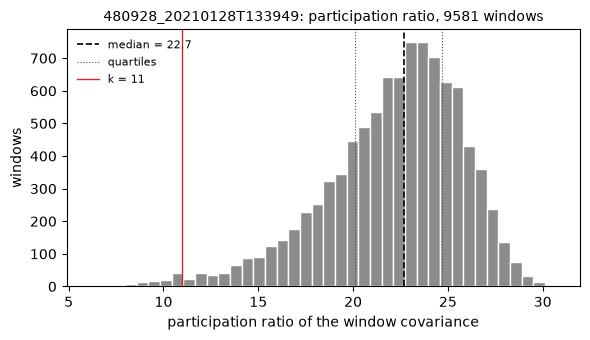

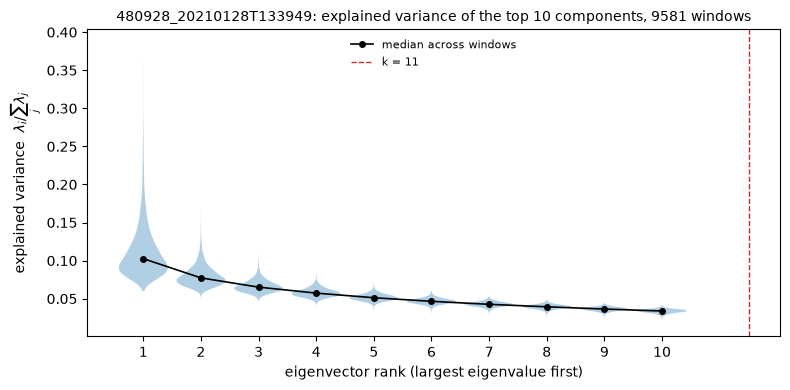

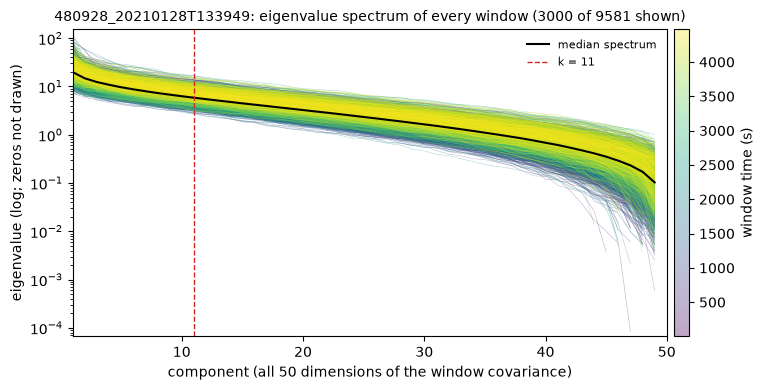

In [15]:
# ============ spectra: participation ratio, explained variance (top 10, violins), raw eigenvalues ============
obj.plot_participation_ratio(); plt.show()
obj.plot_explained_variance(n_show=10); plt.show()      # lambda_i / sum(lambda) per component, median traced; not cumulative
obj.plot_eigenvalue_spectra(); plt.show()               # every window's spectrum over all dimensions, coloured by time

In [16]:
# ============ 4. Gr(k, N): Karcher mean, log map at the mean, tangent PCA, subspace velocity ============
obj.fit_grassmann(mean="karcher")       # mean="extrinsic" is faster and gives the same picture to first order
# per-window results now on st: st.distance (geodesic distance to the mean), st.angles (principal angles),
# st.tangent_coords (top tangent PCs), st.velocity (angle between consecutive windows), st.U, st.mu

Gr(11, 208) for '480928_20210128T133949' in 215.9s: 9581 of 9581 windows (rank >= k)
  Karcher mean: 50 iterations, final gradient norm 1.50e-02 (not below tol=1e-06; raise karcher_iters)
  geodesic distance to the mean: median 4.464 rad (RMS principal angle 77.1 deg); max possible = sqrt(k)*pi/2 = 5.210
  tangent PCA: top 3 directions carry 1.2%, 0.8%, 0.7% of the tangent variance
  angle between consecutive windows: median 3.205 rad


namespace(key='480928_20210128T133949',
          units=     unit_id     region cell_type quality  n_spikes  \
                0        166  right ALM              good      8656   
                1        167  right ALM              good      8023   
                2        168  right ALM              good     18198   
                3        169  right ALM              good      8943   
                4        170  right ALM              good      2404   
                ..       ...        ...       ...     ...       ...   
                203      369  right ALM              good      4801   
                204      370  right ALM              good       602   
                205      371  right ALM              good     19952   
                206      372  right ALM              good      1158   
                207      373  right ALM              good      2064   
                
                                                           spike_times   rate_hz  
        

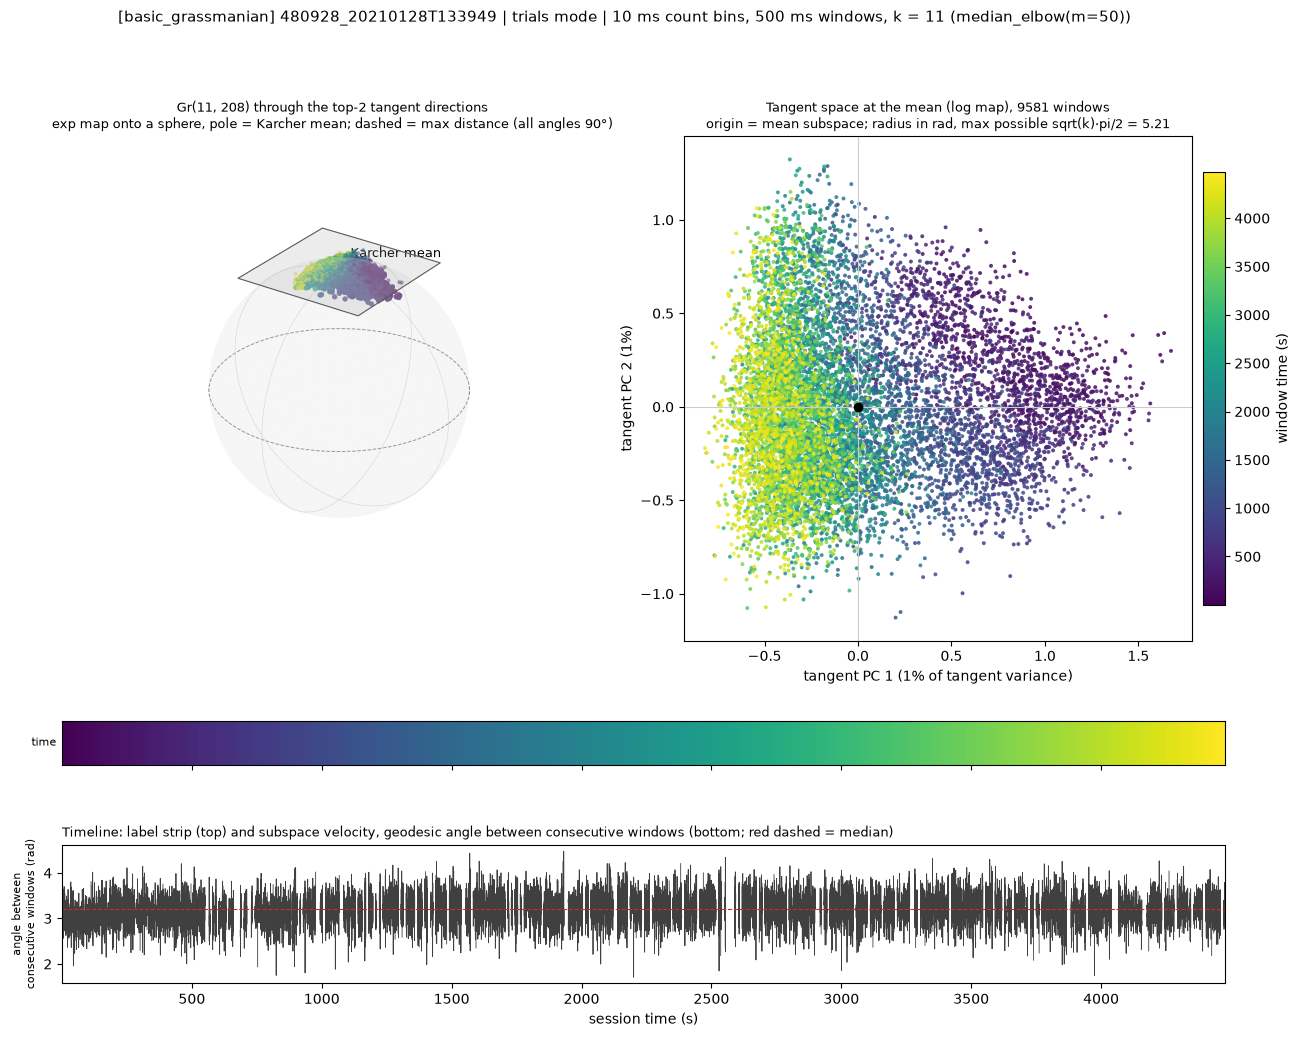

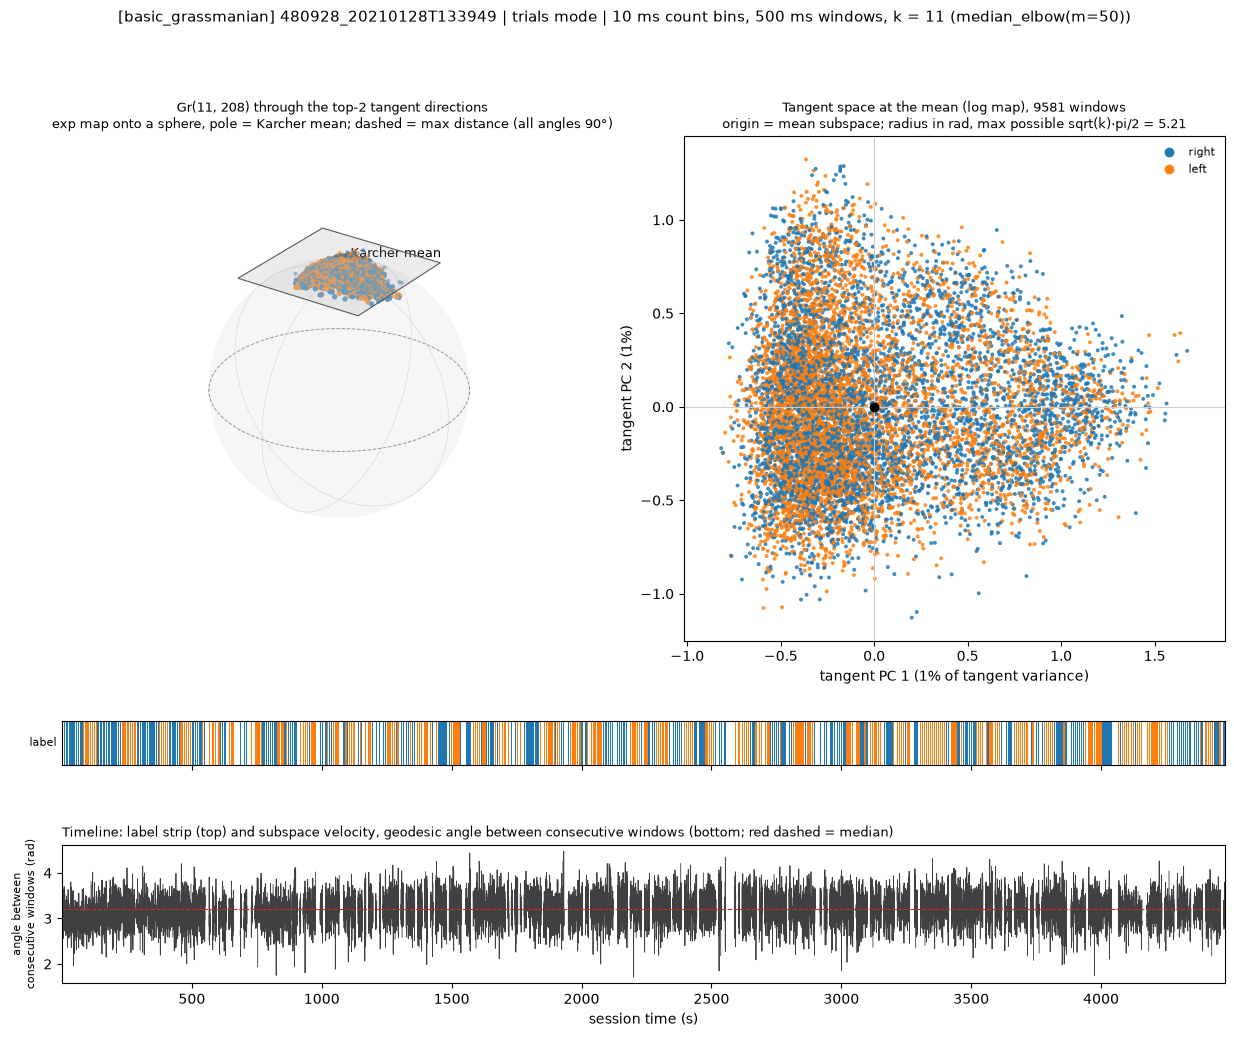

In [17]:
# ============ 5. sphere + tangent plane + timeline ============
# with ipympl installed, `%matplotlib widget` at the top of the notebook makes the sphere drag-to-rotate;
# otherwise turn it with view=(elev, azim)
fig = obj.plot_grassmann(view=(28, -55))                                   # colour = time
plt.show()
fig = obj.plot_grassmann(labels=obj.window_labels("trial_instruction"))    # colour = trial instruction (left / right)
plt.show()

### Knobs worth turning next

* `MOLLIFICATION_BIN_MS` vs `COUNT_BIN_MS`: a window of L count bins has covariance rank ≤ L − 1, so
  with more units than bins per window the spectra are truncated (the window-spectra printout says so).
* `k_rule`: `k_median_elbow(m=..)` (elbow of the first m components) or `k_fixed(K)`; `K_STORE`
  bounds k without recomputing the spectra.
* `normalize` / `count_transform`: hand in any `f(array) -> array`, e.g. `sqrt_counts` before the z-score.
* `obj.plot_grassmann(view=(elev, azim))` to turn the sphere; with `ipympl` installed,
  `%matplotlib widget` at the top makes it drag-to-rotate.
* Caches: change `RUN_NAME` for a fresh run folder, `use_cache=False` to force recomputation,
  `obj.load(key, refresh=True)` to re-read a session from its source.
* Other sessions: `obj.status()` lists what is registered; `obj.load(key)` then `obj.prepare(key)` …
  run the same cells on it; `obj.unload(key)` frees memory.